In [62]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

im.shape=(360, 640, 3)
im.dtype=dtype('uint8')


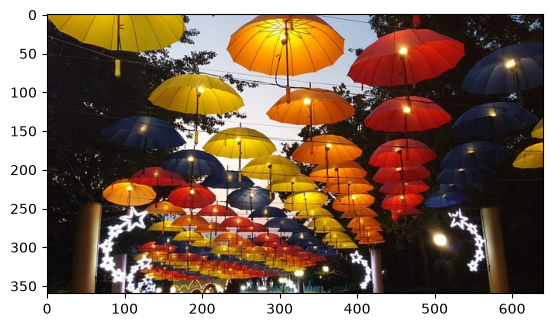

In [63]:
ime_slike = 'umbrellas.jpg'
im = cv2.imread(ime_slike)
im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

print (f'{im.shape=}')
print (f'{im.dtype=}')

plt.clf()
plt.imshow(im)
plt.show()

img_float.shape=(360, 640, 3)


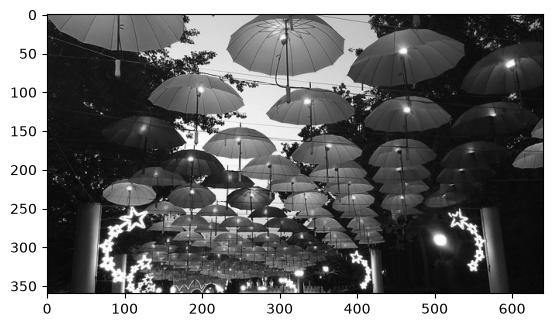

In [64]:
img_float = im.astype(np.float32) / 255.0

print(f'{img_float.shape=}')

#R + G + B / 3
gray = np.mean(img_float, axis=2)

plt.imshow(gray, cmap='gray')

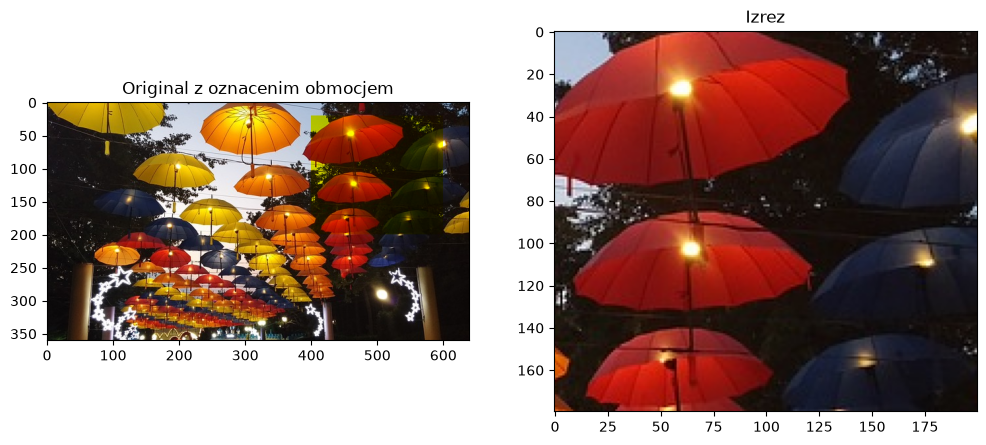

In [65]:
cropped = im[20:200, 400:600]
marked_section = im.copy()
marked_section[20:200, 400:600, 2] = 0

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(marked_section)
plt.title("Original z oznacenim obmocjem")

plt.subplot(1, 2, 2)
plt.imshow(cropped)
plt.title("Izrez")

plt.show()


inverted.shape=(360, 640)
inverted.dtype=dtype('float32')
inverted[0,0]=np.float32(0.36862746)


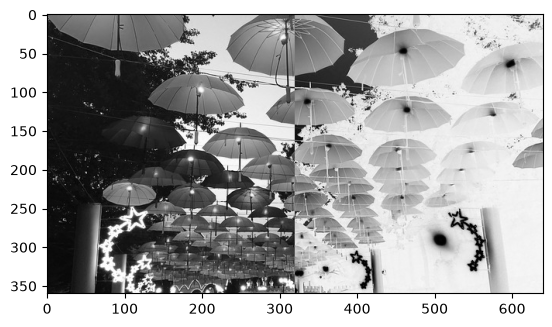

In [66]:
inverted = gray.copy()
inverted [0:360, 320:650] = 1 - inverted[0:360, 320:650]

print(f'{inverted.shape=}')
print(f'{inverted.dtype=}')
print(f'{inverted[0,0]=}')
plt.imshow(inverted, cmap='gray')

gray.shape=(360, 640)


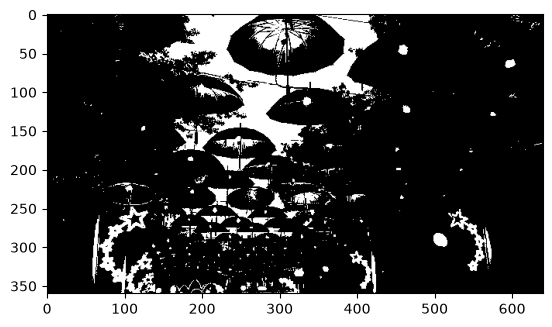

In [67]:
binarno = gray.copy()
binarno = (binarno * 255).astype(np.uint8)

print(f'{gray.shape=}')

binarno[binarno < 150] = 0
binarno[binarno >= 150] = 255

plt.imshow(binarno, cmap='gray')

## 2. Kamera

#### a.)

f = 10cm  
Z = 14m  
H = 5m  

$$h = -f\frac{H}{Z}$$
$$h = -10cm\frac{5m}{14m}$$
$$h = -10cm\frac{500cm}{1400cm}$$
$$h = -3.57cm


#### b.)

f = 10cm  
Z = 10m  
H = 2.5m  
a = 0.5 $\frac{m}{s^2}$  
t = 30s  
interval = 10m

In [68]:
def camera_size (focal_length, real_size, distance):
    return abs((-focal_length * real_size) / distance)

Text(0, 0.5, 'Size [cm]')

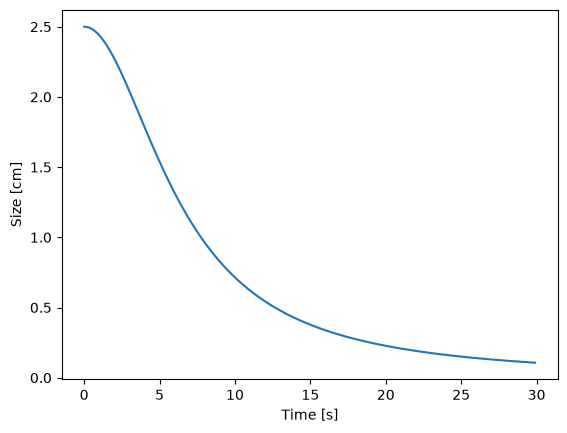

In [69]:

sizes = []
times = []
acceleration = 50
time = 0

for time in range(0, 300):
    sizes.append(camera_size(10, 250, 1000 + (0.5 * acceleration * time/10 * time/10)))
    times.append(time/10)
    
    

plt.plot(times,sizes)
plt.xlabel("Time [s]")
plt.ylabel("Size [cm]")
    

#### c.)
Lece so veliko drazje in bolj kompleksne kot kamere z luknjico, imajo pa veliko prednost, da lahko osredotocajo svetlobo na senzor, kar vodi k svetlejsim slikam.

#### d.)

f = 60mm  
Z = 95m  
h(px) = 250px
p = 2500 DPI

conversion: 1 inch = 2.54cm


$$ h = \frac {h(px)}{p} $$
$$ h = \frac {200px}{2500 px/inch} $$
$$ h = 0.08 inch$$
$$ h = 0.2032 cm$$
$$ h = 2.032 mm$$

---
$$ H = \frac {hZ}{f} $$
$$ H = \frac {2.032mm * 95m}{60mm} $$
$$ H = \frac {193040000mm}{60mm} $$
$$ H = 3217333 mm $$
$$ H = 3.22m $$



#### e.)

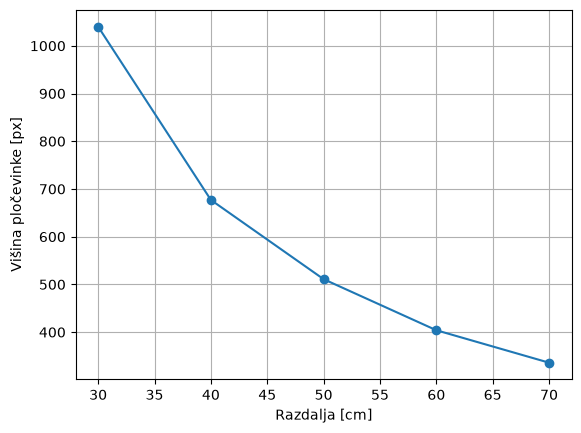

In [70]:

distances = np.array([30, 40, 50, 60, 70])
heights = np.array([1040, 677, 511, 404, 336])

plt.plot(distances, heights, 'o-')
plt.xlabel("Razdalja [cm]")
plt.ylabel("Višina pločevinke [px]")
plt.grid()
plt.show()


$$ \frac {h1}{h2} = \frac {Z1}{Z2} $$
$$ {h2} = h1* \frac {Z1}{Z2} $$
$$ {h2} = 336px * \frac {70cm}{80cm} $$
$$ h2 = 294px $$
---
Actual measured = 287px

In [71]:
predicted = 336 * (70 / 80)
measured = 287

error = abs(predicted - measured)
relative_error = error / measured * 100

print(f"Predicted: {predicted:.1f} px")
print(f"Error: {error:.1f} px ({relative_error:.2f}%)")

Predicted: 294.0 px
Error: 7.0 px (2.44%)


## 3. Histogrami

#### a.)

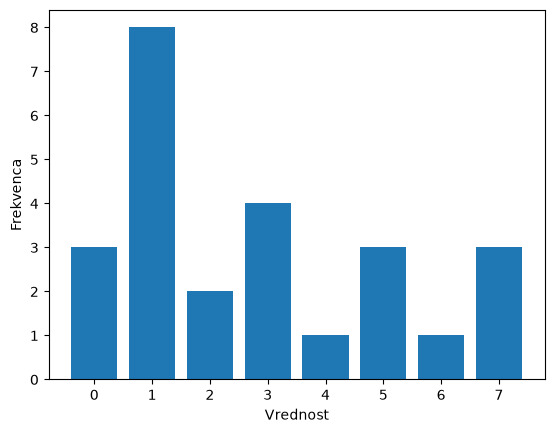

In [72]:
values = range(8)
frequencies = [3, 8, 2, 4, 1, 3, 1, 3]

plt.bar(values, frequencies)
plt.xlabel("Vrednost")
plt.ylabel("Frekvenca")
plt.show()

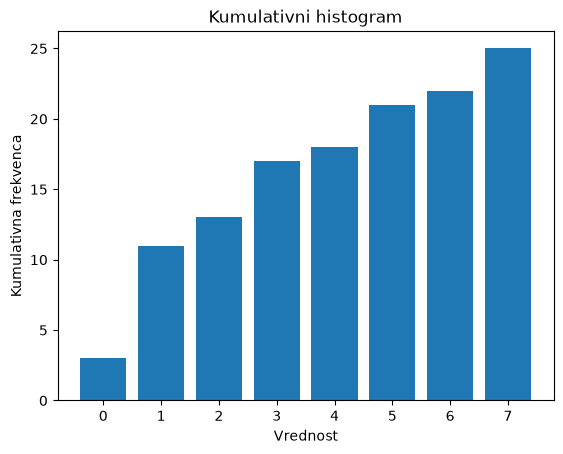

In [73]:

# Kumulativni histogram
cumulative = np.cumsum(frequencies)

plt.title("Kumulativni histogram")
plt.bar(values, cumulative)
plt.xlabel("Vrednost")
plt.ylabel("Kumulativna frekvenca")
plt.show()

#### c.)

Ce bi bila matrika 4 bitna bi sle vrednosti na njej do 16. Histogram bi bil se enkrat vecji.

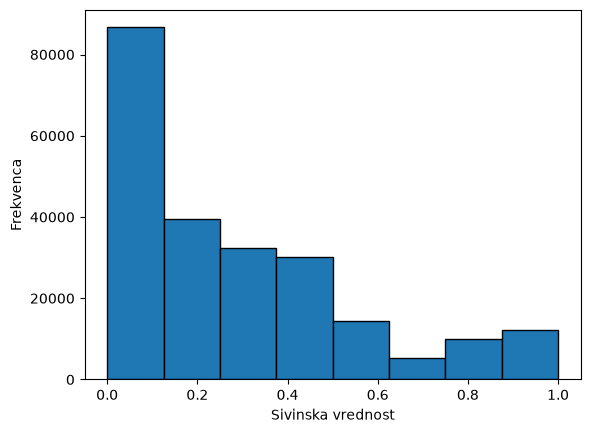

In [74]:

histogram = np.histogram(gray, bins=8)

plt.bar(
    histogram[1][:-1],
    histogram[0],
    width=np.diff(histogram[1]),
    align='edge',
    edgecolor='black'
)

plt.xlabel("Sivinska vrednost")
plt.ylabel("Frekvenca")
plt.show()


In [75]:
def histogram_stretch(image):
    
    min_val = np.min(image)
    max_val = np.max(image)
    
    image = 255 * ((image - min_val) / (max_val - min_val))
    return image

In [76]:
phone = cv2.imread('phone.jpg', cv2.IMREAD_GRAYSCALE)
type(phone)
phone.shape

phone8 = phone.astype(np.uint8)

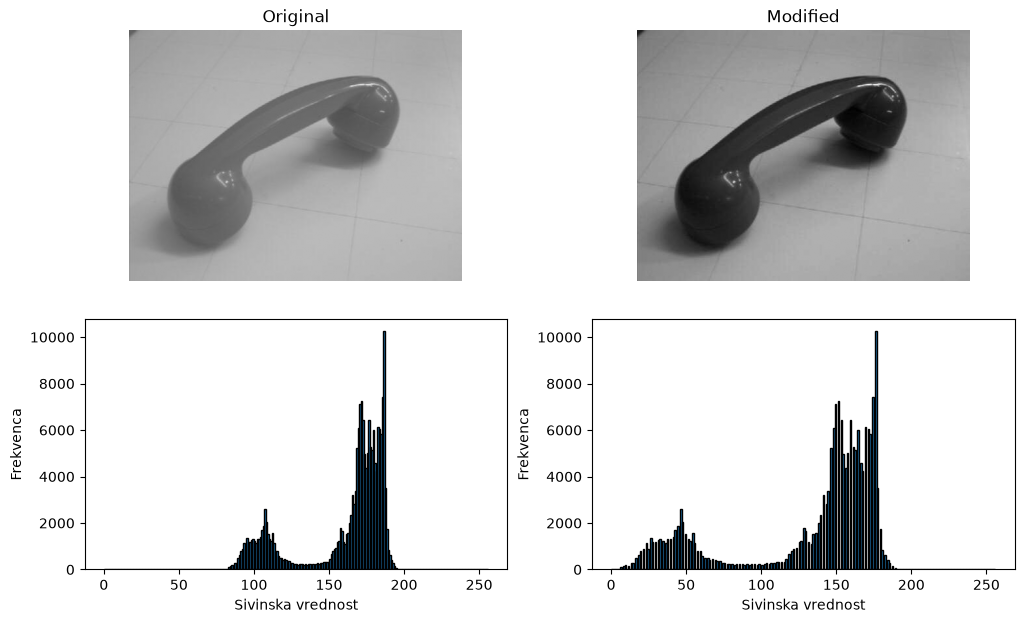

In [77]:

phone = cv2.imread('phone.jpg', cv2.IMREAD_GRAYSCALE)

fig, ax = plt.subplots(2, 2, figsize=(12, 7))

images = [phone, histogram_stretch(phone)]
titles = ["Original", "Modified"]

for i in range(2):
    ax[0, i].imshow(images[i], cmap='gray', vmin=0, vmax=255)
    ax[0, i].set_title(titles[i])
    ax[0, i].axis('off')

    histogram = np.histogram(images[i], bins=256, range=(0, 256))

    ax[1, i].bar(
        histogram[1][:-1],
        histogram[0],
        width=np.diff(histogram[1]),
        align='edge',
        edgecolor='black'
    )

    ax[1, i].set_xlabel("Sivinska vrednost")
    ax[1, i].set_ylabel("Frekvenca")

plt.subplots_adjust(hspace=0.15, wspace=0.2)
plt.show()


threshold=140.0


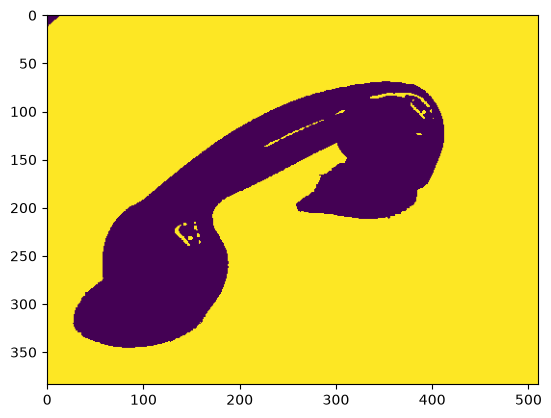

In [78]:
threshold, binary = cv2.threshold(phone, 0, 255, cv2.THRESH_OTSU)

print(f"{threshold=}")

plt.imshow(binary)


#### g.)
Deluje najbolje ko imamo subjekt in ozadje, ki imata med sabo visok kontrast. Ali bolj natancno ko imamo bimodalni histogram (histogram z dvema vrhovoma)

## 4. Barvni prostor

In [79]:
import matplotlib

print(matplotlib.colors.rgb_to_hsv([1,34/255,126/255]))

[0.9306184  0.86666667 1.        ]


#### a.)
Pretvori RGB v HSV: (255,34,126)

$$ M = max(255, 34, 126) $$
$$ M = 255 (R) $$
<br>

$$ m = min(255, 34, 126) $$
$$ m = 34 $$

<br>

$$ d = M - m $$
$$ d = 255 - 34 $$
$$ d = 221 $$

---

$$ H = 60 * (\frac {G - B} d + 6 mod 6) $$
$$ H = 60 * (\frac {-92} {221} + 6 mod 6)$$
$$ H = 60 * (\frac {1234} {221} mod 6)$$
$$ H = 60 * 5.583 $$
$$ H = 335.02 $$
 <br>

$$ S = \frac d M $$
$$ S = \frac {221} {255} $$
$$ S = 0.87 $$
<br>

$$ V = M $$
$$ V = 255 $$

---

$$ HSV = (335, 0.87, 1) $$



#### b.)
HSV 2 RGB -> (0.65, 0.7, 0.15)

$$ C = S * V $$
$$ C = 0.7 * 0.15 $$
$$ C = 0.105$$
<br>

$$ X = C * (1-|(6H mod 2) - 1|) $$
$$ X = 0.105 * (1 - |(6 * 0.65 mod 2) - 1|) $$
$$ X = 0.105 * (1 - |1.9 - 1|) $$
$$ X = 0.105 * (1 - 0.9) $$
$$ X = 0.105 * 0.1 $$
$$ X = 0.0105 $$
<br>

$$ m = V - C $$
$$ m = 0.15 - 0.105 $$
$$ m = 0.045 $$

---

$$ RGB = (R' + m, G' + m, B' + m) $$
$$ RGB = (0 + m, X + m, C + m) $$
$$ RGB = (0.045, 0.0105 + 0.045, 0.105 + 0.045) $$
$$ RGB = (0.045, 0.0555, 0.15)



In [81]:
matplotlib.colors.hsv_to_rgb([0.65, 0.7, 0.15])

array([0.045 , 0.0555, 0.15  ])

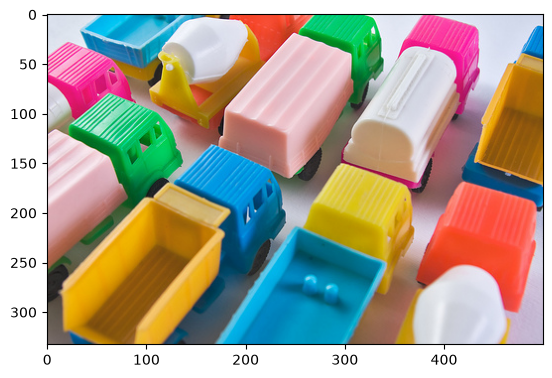

In [90]:
trucks = cv2.imread("trucks.jpg")
trucks_rgb = cv2.cvtColor(trucks, cv2.COLOR_BGR2RGB)

plt.imshow(trucks_rgb)
plt.show()

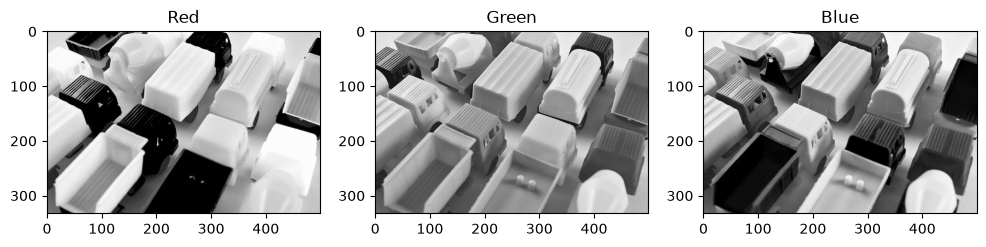

In [92]:
R = trucks_rgb[:, :, 0]
G = trucks_rgb[:, :, 1]
B = trucks_rgb[:, :, 2]

fig, ax = plt.subplots(1, 3, figsize=(12, 4))

ax[0].imshow(R, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Red")

ax[1].imshow(G, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Green")

ax[2].imshow(B, cmap="gray", vmin=0, vmax=255)
ax[2].set_title("Blue")

plt.show()

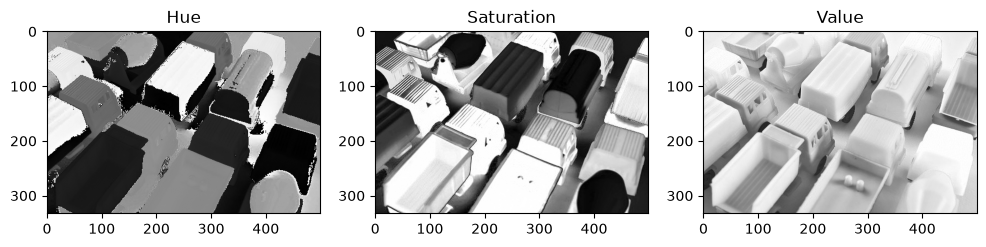

In [98]:
rgb_float = trucks_rgb.astype(np.float32) / 255.0

hsv = cv2.cvtColor(rgb_float, cv2.COLOR_RGB2HSV)

#hsv rabimo med 0 in 1 ne med 0 in 360

hsv[:, :, 0] /= 360

H = hsv[:, :, 0]
S = hsv[:, :, 1]
V = hsv[:, :, 2]

fig, ax = plt.subplots(1, 3, figsize=(12, 4))

ax[0].imshow(H, cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Hue")

ax[1].imshow(S, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Saturation")

ax[2].imshow(V, cmap="gray", vmin=0, vmax=1)
ax[2].set_title("Value")

plt.show()

In [108]:
def blue_threshold(img, threshold = 150):
    _, binary = cv2.threshold(img[:,:,2], threshold, 255, cv2.THRESH_BINARY)
    return binary

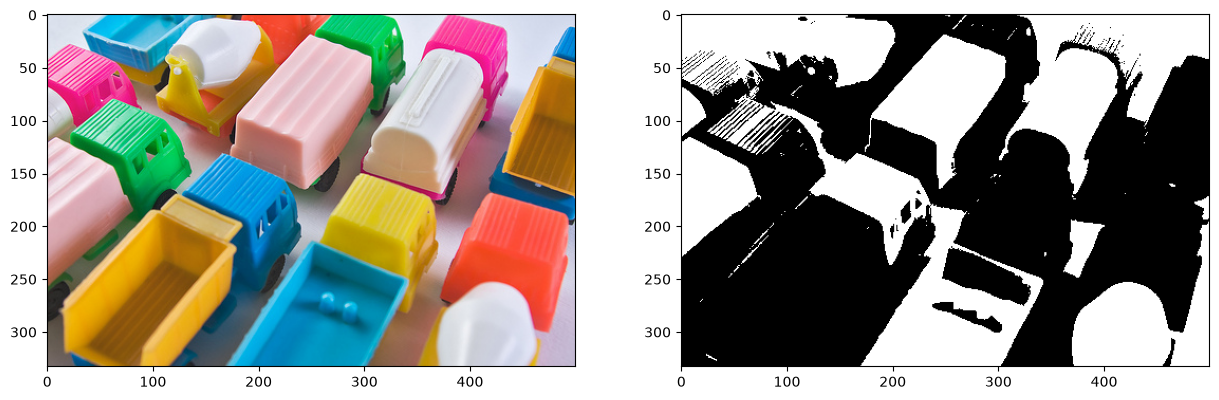

In [109]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].imshow(trucks_rgb)
ax[1].imshow(blue_threshold(trucks_rgb), cmap = 'grey')

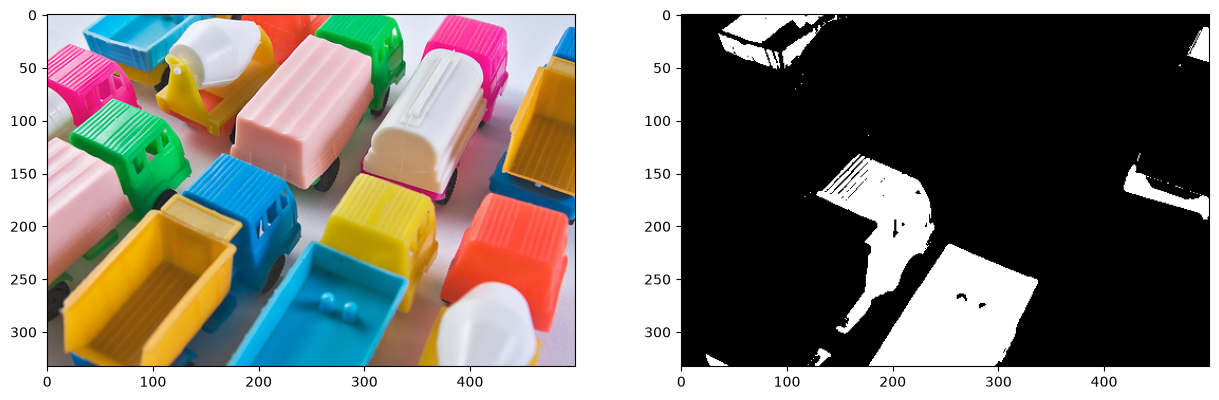

In [122]:
#Brez keepdims nam sestevanje da 2 dimenzinalno matriko
rgb_sum = np.sum(rgb_float,axis=2,keepdims=True)
#Delimo modro iz originalne slike z vsemi kanali sestetimi kot v formuli
rgb_normalized = np.divide(rgb_float, rgb_sum)

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].imshow(trucks_rgb)
ax[1].imshow(blue_threshold(rgb_normalized, 0.5), cmap = 'grey')


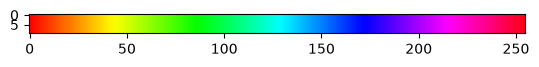

In [124]:
plt.figure()
plt.imshow(np.meshgrid(np.linspace(0, 1, 255), np.ones((10, 1)))[0], 
cmap=plt.cm.hsv)
plt.show()

In [132]:
def hsv_threshold(img, min, max):
    
    H = img[:,:, 0]
    
    mask = (H>=min) & (H<=max)
    return mask

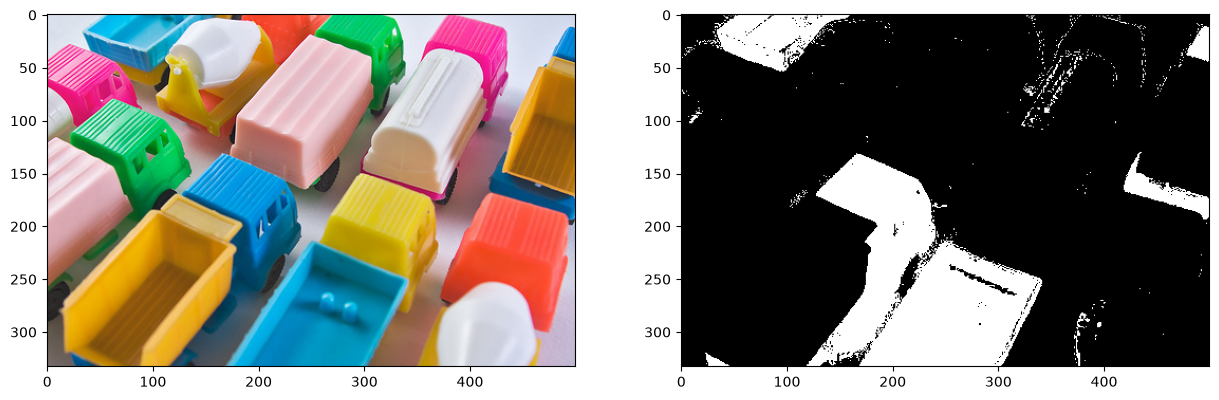

In [162]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].imshow(trucks_rgb)
ax[1].imshow(hsv_threshold(hsv, 134/255, 150/255), cmap = 'grey')

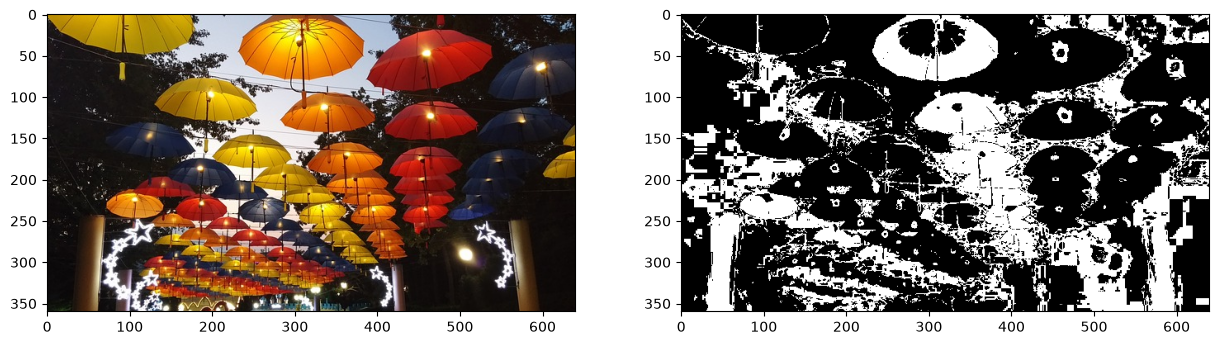

In [178]:
umbrellas_hsv = cv2.cvtColor(im.astype(np.float32) / 255.0, cv2.COLOR_RGB2HSV)

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].imshow(im)
ax[1].imshow(hsv_threshold(umbrellas_hsv, 15, 40), cmap = 'grey')

In [181]:
def im_mask(image, mask):
    
    masked_image = image.copy()
    masked_image[~mask] = 0
    return masked_image


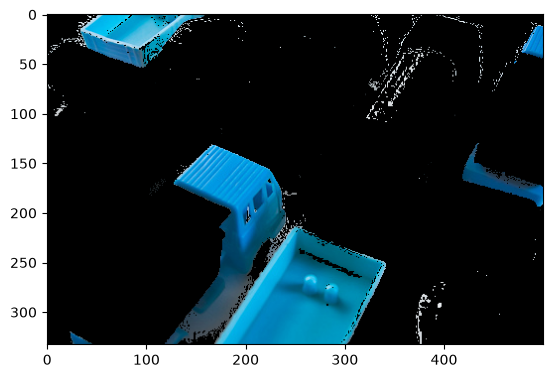

In [182]:
plt.imshow(im_mask(trucks_rgb, hsv_threshold(hsv, 134/255, 150/255)))

## 5. Regije in morfološke operacije